In [1]:
%load_ext rpy2.ipython

/Users/arturohernanzcarrasco-munoz/code/analisis_datos_clasificacion/.venv/lib/python3.9/site-packages/rpy2/ipython/rmagic.py:96: UserWarning: The Python package `pandas` is strongly recommended when using `rpy2.ipython`. Unfortunately it could not be loaded, as we did not manage to load `numpy` in the first place (error: No module named 'numpy').
  warnings.warn('The Python package `pandas` is strongly '


In [2]:
%%R
lib_loc <- "lib_loc"

In [4]:
%%R
os <- Sys.info()[["sysname"]]

Cargamos librerias

In [ ]:
%%R
options(repos = c(CRAN = "https://cloud.r-project.org"))

if (!require("psych", lib.loc = lib_loc)) install.packages("psych", lib = lib_loc)
library(psych, lib.loc = lib_loc)
if (!require("plyr", lib.loc = lib_loc)) install.packages("plyr", lib = lib_loc)
library(plyr, lib.loc = lib_loc)
if (!require("Rmisc", lib.loc = lib_loc)) install.packages("Rmisc", lib = lib_loc)
library(Rmisc, lib.loc = lib_loc)
if (!require("dplyr", lib.loc = lib_loc)) install.packages("dplyr", lib = lib_loc)
library(dplyr, lib.loc = lib_loc)
if (!require("GGally", lib.loc = lib_loc)) install.packages("GGally", lib = lib_loc)
library(GGally, lib.loc = lib_loc)
if (!require("corrplot", lib.loc = lib_loc)) install.packages("corrplot", lib = lib_loc)
library(corrplot, lib.loc = lib_loc)

if(os=="Darwin"){
    if (!require("leaps", lib.loc = lib_loc)) install.packages("leaps_3.2.tgz", lib = lib_loc, repos = NULL, type = "mac.binary")
    library(leaps, lib.loc = lib_loc)
}
else{
    if (!require("leaps", lib.loc = lib_loc)) install.packages("leaps", lib = lib_loc)
    library(leaps, lib.loc = lib_loc)
}

Loading required package: psych
Loading required package: plyr
Loading required package: Rmisc
Loading required package: lattice
Loading required package: dplyr

Attaching package: ‘dplyr’

The following objects are masked from ‘package:plyr’:

    arrange, count, desc, failwith, id, mutate, rename, summarise,
    summarize

The following objects are masked from ‘package:stats’:

    filter, lag

The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union

Loading required package: GGally
Loading required package: ggplot2

Attaching package: ‘ggplot2’

The following objects are masked from ‘package:psych’:

    %+%, alpha

Loading required package: corrplot
corrplot 0.95 loaded
Loading required package: leaps


# Carga del fichero

In [80]:
%%R

dfMedidas <- read.csv("apartment+for+rent+classified/apartments_for_rent_classified_10K.csv", 
                      sep = ";", dec = ".", 
                      check.names = FALSE, 
                      stringsAsFactors = TRUE, 
                      header = TRUE, 
                      fill = TRUE)


# Visualizamos los datos

In [81]:
%%R
head(dfMedidas, 5)

          id               category
1 5668626895 housing/rent/apartment
2 5664597177 housing/rent/apartment
3 5668626833 housing/rent/apartment
4 5659918074 housing/rent/apartment
5 5668626759 housing/rent/apartment
                                                                title
1 Studio apartment 2nd St NE, Uhland Terrace NE, Washington, DC 20002
2                                   Studio apartment 814 Schutte Road
3         Studio apartment N Scott St, 14th St N, Arlington, VA 22209
4                                      Studio apartment 1717 12th Ave
5         Studio apartment Washington Blvd, N Cleveland St, Arlington
                                                                                                                                                                                     body
1 This unit is located at second St NE, Uhland Terrace NE, Washington, DC 20002, Washington, 20002, DCMonthly rental rates range from $790 - $1090We have studio units available f

Analizamos los tipos de variables

In [82]:
%%R
str(dfMedidas)

'data.frame':	10000 obs. of  22 variables:
 $ id           : num  5.67e+09 5.66e+09 5.67e+09 5.66e+09 5.67e+09 ...
 $ category     : Factor w/ 3 levels "housing/rent/apartment",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ title        : Factor w/ 9350 levels "$1,010 / Two BR - Great Deal. MUST SEE. Pet OK!",..: 5997 6365 6452 5823 6468 82 5936 6455 6056 6427 ...
 $ body         : Factor w/ 9961 levels "---- SCHEDULE A PROPERTY GO TO OUR WEB SITEAT: Listedbuy. com/lt/2e8697d0f9 ---- Terrific location just steps a"| __truncated__,..: 9391 8488 9281 4394 9530 33 5318 9310 6140 8996 ...
 $ amenities    : Factor w/ 2255 levels "AC","AC,Alarm,Cable or Satellite,Clubhouse,Dishwasher,Fireplace,Garbage Disposal,Internet Access,Parking,Patio/Deck,"| __truncated__,..: 2137 2137 2137 2137 2137 1587 2137 2137 2239 2137 ...
 $ bathrooms    : Factor w/ 15 levels "1","1.5","2",..: 15 15 1 1 15 1 15 15 1 15 ...
 $ bedrooms     : Factor w/ 11 levels "0","1","2","3",..: 1 2 1 1 1 1 1 1 1 1 ...
 $ currency     : Factor

# EDA

Como podemos observar hay un total de 8760 instancias con 14 variables.
Estas variables se pueden dividir en categóricas, numéricas y una ordinal:

1)   Categóricas:
* category (Variable Objetivo): Categoría de la casa
* title: Título de la oferta
* body: Cuerpo de la oferta
* amenities: Comodidades
* currency: Moneda en la que está el precio
* has_photo: Tiene foto del apartamento o no
* pets_allowed: Permite o no mascotas (None, o lista con las opciones)
* price_display: Precio pero con el símbolo de la moneda en la que está
* price_type: Tipo de pago (Mensual, ...)
* cityname: Ciudad
* state: Estado
* source: Plataforma donde está la oferta


2)   Numéricas:
* id: Identificador de la casa
* bathrooms: Número de baños
* price: Precio de la casa (Número)
* latitude: Coordenada de latitud
* longitude: Coordenada de longitud
* address: Dirección
* fee: Señal (Número o "No")
* square_feet: Metros cuadrados

3) Ordinales:
* time: Tiempo desde que se creó la oferta


Cabe destacar que muchos de los valores numéricos no son de tipo entero, por lo que habrá que tratar los datos antes de tratar con ellos.
Por otro lado, muchos de los campos tienen el valor "null" para denotar falta de datos, sin embargo, no se clasifican como valores faltantes.

Para conocer los datos con más detalle hay que evaluar los siguientes conceptos:


*   Columnas faltantes o irrelevantes
*   Variables categóricas con mayor cardinalidad
*   Variables con valores faltantes
*   Correlación de las variables numéricas

In [83]:
%%R
describe(dfMedidas)

               vars     n         mean          sd       median      trimmed
id                1 10000 5.623396e+09 70210252.04 5668609592.5 5.632060e+09
category*         2 10000 1.000000e+00        0.03          1.0 1.000000e+00
title*            3 10000 4.579810e+03     2745.65       4624.5 4.564860e+03
body*             4 10000 4.978490e+03     2883.11       4976.5 4.977060e+03
amenities*        5 10000 1.701780e+03      610.95       2073.0 1.812630e+03
bathrooms*        6 10000 1.810000e+00        1.45          1.0 1.550000e+00
bedrooms*         7 10000 2.750000e+00        0.97          3.0 2.620000e+00
currency*         8 10000 1.000000e+00        0.00          1.0 1.000000e+00
fee*              9 10000 1.000000e+00        0.00          1.0 1.000000e+00
has_photo*       10 10000 2.070000e+00        0.32          2.0 2.000000e+00
pets_allowed*    11 10000 2.970000e+00        1.29          2.0 2.900000e+00
price            12 10000 1.486280e+03     1076.51       1270.0 1.331120e+03

En este caso podemos ver que hay algunas columnas irrelevantes, ya sea por ser de id o que no aporten información como id; title; body; price_display; address, o amenities o por ser de valores constantes como fee y currency.

En cuanto a la cardinalidad máxima podemos ver que la variable con mayor rango es el nombre de la ciudad, alcanzndo los 1574 valores.

En cuanto a los valores faltantes, hay que tratar los datos para que se identifiquen los null como valores nulos

Transformamos los valores nulos para que se detecten como tal y luego eliminaremos las columnas innecesarias

In [84]:
%%R

dfMedidas <- read.csv("apartment+for+rent+classified/apartments_for_rent_classified_10K.csv", 
                      sep = ";", dec = ".", 
                      check.names = FALSE, 
                      stringsAsFactors = TRUE, 
                      na.strings = c("null"),
                      header = TRUE, 
                      fill = TRUE)

In [85]:
%%R

dfMedidas <- dfMedidas[,!names(dfMedidas) %in% c("id", "title", "body", "price_display", "address", "amenities", "fee", "currency")]

In [86]:
%%R
describe(dfMedidas)

              vars     n          mean         sd        median       trimmed
category*        1 10000          1.00       0.03          1.00          1.00
bathrooms        2  9966          1.38       0.62          1.00          1.27
bedrooms         3  9993          1.74       0.94          2.00          1.62
has_photo*       4 10000          2.07       0.32          2.00          2.00
pets_allowed*    5  8252          2.54       0.98          2.00          2.50
price            6 10000       1486.28    1076.51       1270.00       1331.12
price_type*      7 10000          1.00       0.02          1.00          1.00
square_feet      8 10000        945.81     655.76        802.00        863.80
cityname*        9  9923        727.11     455.05        741.00        720.69
state*          10  9923         27.43      15.37         28.00         27.73
latitude        11  9990         37.70       5.50         38.81         37.56
longitude       12  9990        -94.65      15.76        -93.65 

In [87]:
%%R
str(dfMedidas)

'data.frame':	10000 obs. of  14 variables:
 $ category    : Factor w/ 3 levels "housing/rent/apartment",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ bathrooms   : num  NA NA 1 1 NA 1 NA NA 1 NA ...
 $ bedrooms    : int  0 1 0 0 0 0 0 0 0 0 ...
 $ has_photo   : Factor w/ 3 levels "No","Thumbnail",..: 2 2 2 2 2 2 2 2 2 2 ...
 $ pets_allowed: Factor w/ 4 levels "Cats","Cats,Dogs",..: 4 4 4 4 4 NA 4 4 4 4 ...
 $ price       : int  790 425 1390 925 880 2475 1800 840 1495 890 ...
 $ price_type  : Factor w/ 3 levels "Monthly","Monthly|Weekly",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ square_feet : int  101 106 107 116 125 130 132 136 138 141 ...
 $ cityname    : Factor w/ 1574 levels "Aberdeen","Abilene",..: 1469 450 53 1286 53 822 1447 1469 1248 1469 ...
 $ state       : Factor w/ 51 levels "AK","AL","AR",..: 8 16 46 48 46 35 5 8 5 8 ...
 $ latitude    : num  38.9 38 38.9 47.6 38.9 ...
 $ longitude   : num  -77 -87.7 -77.1 -122.3 -77.1 ...
 $ source      : Factor w/ 12 levels "GoSection8","Home Rentals",..: 10 10 10

Analizamos cada variable con histogramas:

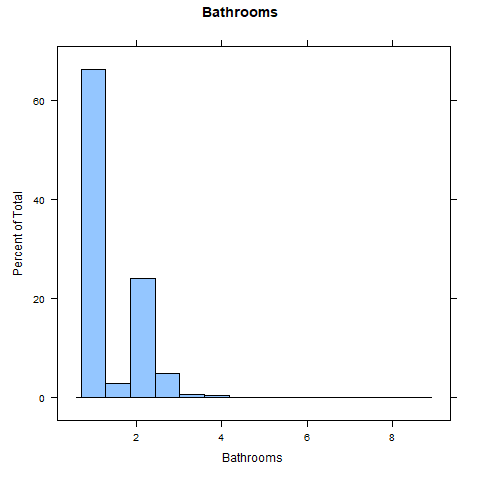

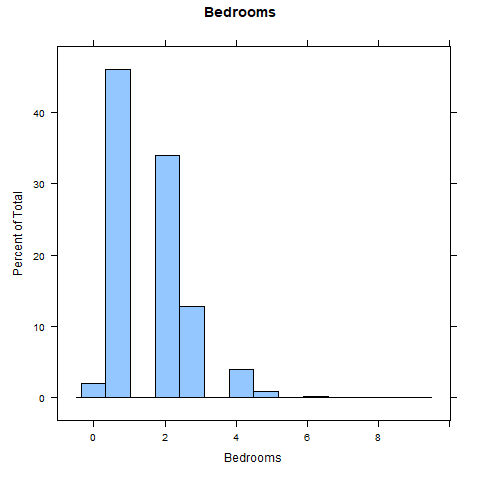

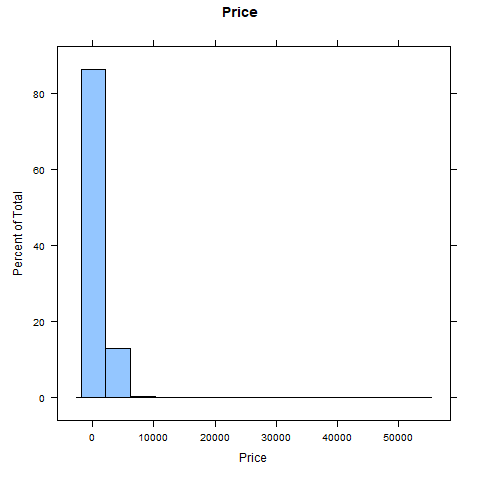

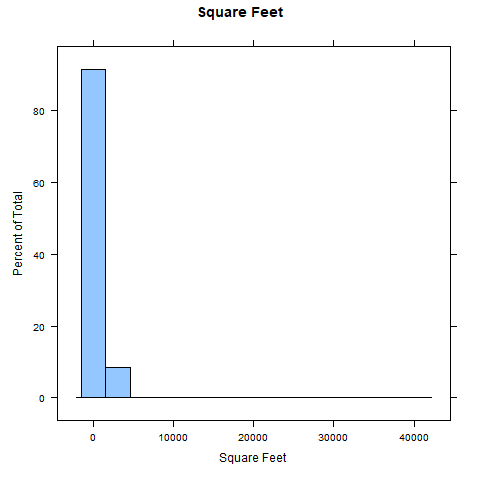

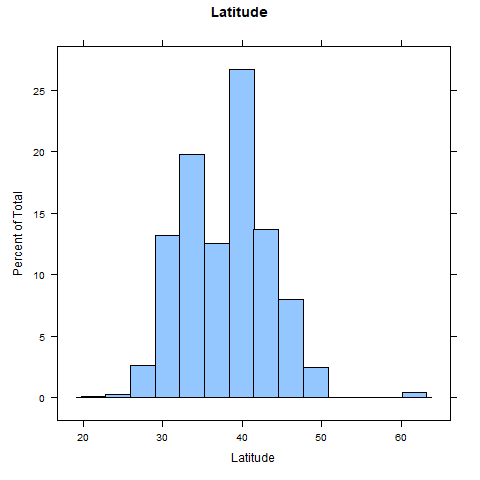

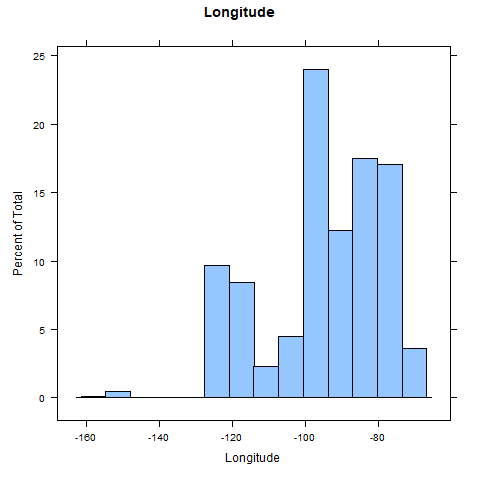

In [88]:
%%R

print(histogram(dfMedidas$bathrooms, main = "Bathrooms", xlab = "Bathrooms"))
print(histogram(dfMedidas$bedrooms, main = "Bedrooms", xlab = "Bedrooms"))
print(histogram(dfMedidas$price, main = "Price", xlab = "Price"))
print(histogram(dfMedidas$square_feet, main = "Square Feet", xlab = "Square Feet"))
print(histogram(dfMedidas$latitude, main = "Latitude", xlab = "Latitude"))
print(histogram(dfMedidas$longitude, main = "Longitude", xlab = "Longitude"))

Podemos ver que todas las variables siguen una distribución normal, y podemos destacar la siguiente información:

* Podemos ver que la mayoría de precios está por debajo de los 10000 y los metros cuadrados tambien.
* Podemos ver que los valores de Longitud se concentran entere 60 y 130 aproximadamente, lo que tiene sentido dado que los Estados Unidos de América están comprendidos entre esas longitudes.
* En cuanto al número de habitaciones y baños podemos ver que, en general, no son muchos.

Evaluamos también la presencia de outliers con los diagramas de caja

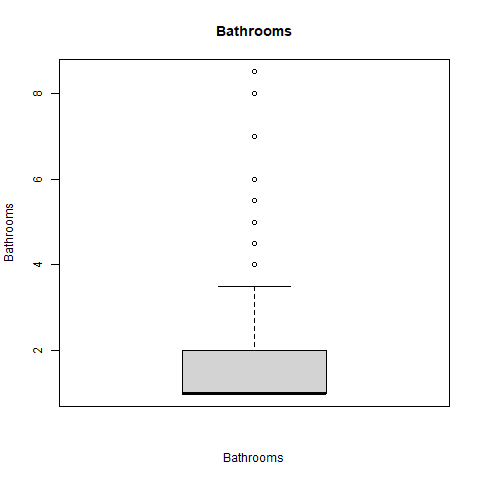

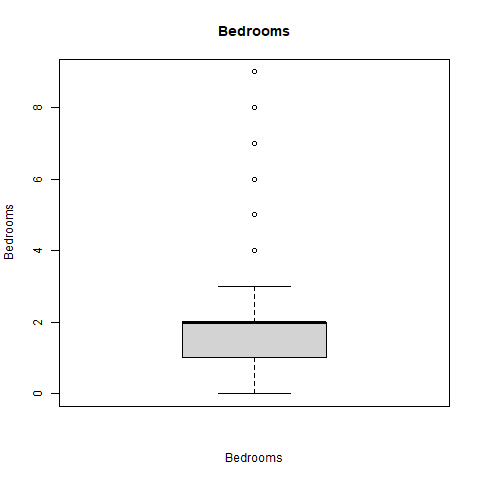

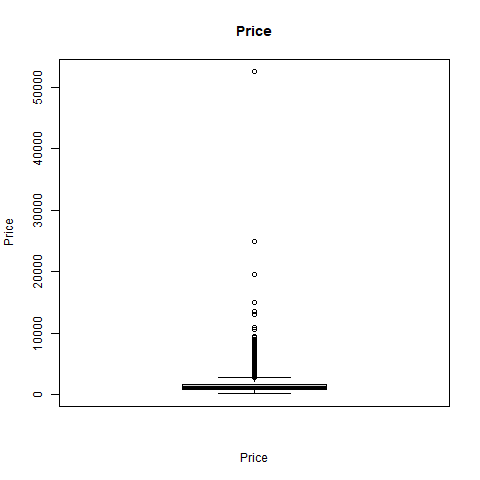

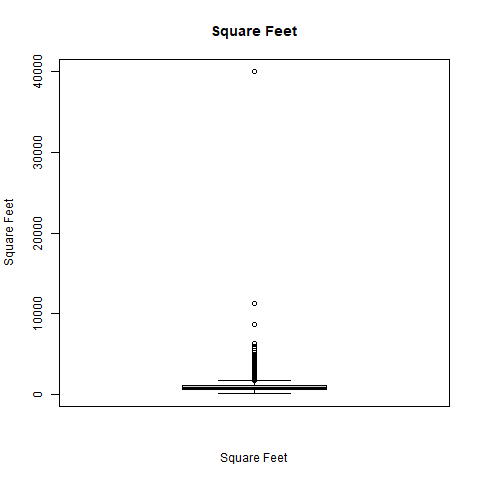

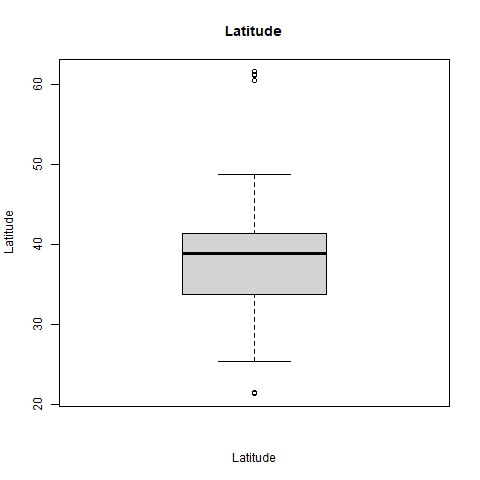

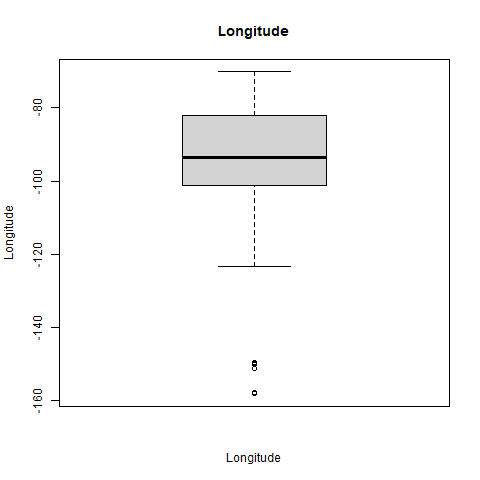

In [89]:
%%R
boxplot(dfMedidas$bathrooms, main = "Bathrooms", xlab = "Bathrooms", ylab = "Bathrooms")
boxplot(dfMedidas$bedrooms, main = "Bedrooms", xlab = "Bedrooms", ylab = "Bedrooms")
boxplot(dfMedidas$price, main = "Price", xlab = "Price", ylab = "Price")
boxplot(dfMedidas$square_feet, main = "Square Feet", xlab = "Square Feet", ylab = "Square Feet")
boxplot(dfMedidas$latitude, main = "Latitude", xlab = "Latitude", ylab = "Latitude")
boxplot(dfMedidas$longitude, main = "Longitude", xlab = "Longitude", ylab = "Longitude")

Podemos ver que todas las variables presentan Outliers, siendo el precio y los metros cuadrados aquellas variables con más, por ello, y para buscar alguna explicación, observamos el impacto de la localización geográfica en estas variables y la objetivo.

In addition: Warning messages:
1: Removed 10 rows containing missing values or values outside the scale range
(`geom_point()`). 
2: Removed 10 rows containing missing values or values outside the scale range
(`geom_point()`). 
3: Removed 10 rows containing missing values or values outside the scale range
(`geom_point()`). 


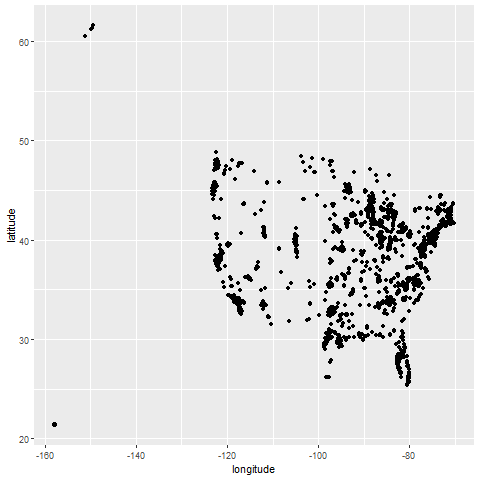

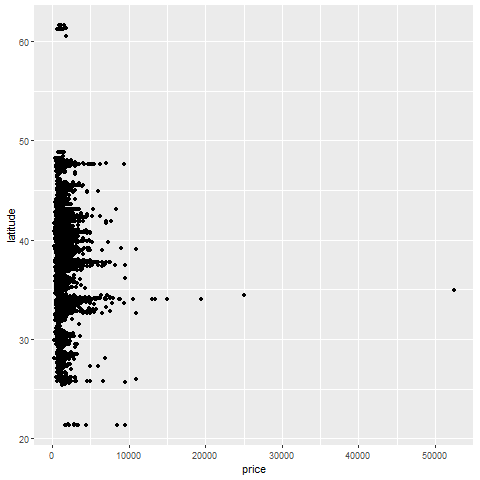

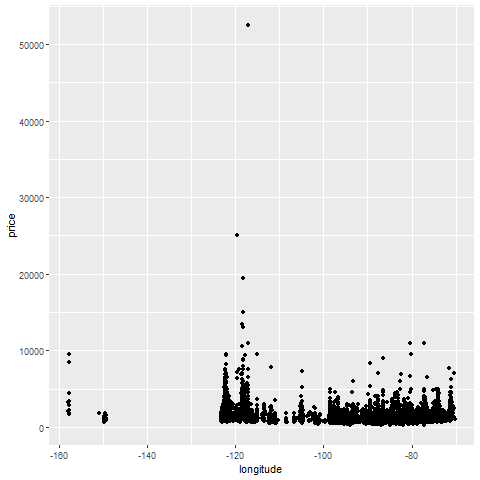

In [90]:
%%R
print(ggplot(dfMedidas, aes(x = longitude, y = latitude)) + geom_point())

print(ggplot(dfMedidas, aes(x = price, y = latitude)) + geom_point())
print(ggplot(dfMedidas, aes(x = longitude, y = price)) + geom_point())

R callback write-console: In addition:   
R callback write-console: Warning message:
  
R callback write-console: Removed 10 rows containing missing values or values outside the scale range
(`geom_point()`). 
  


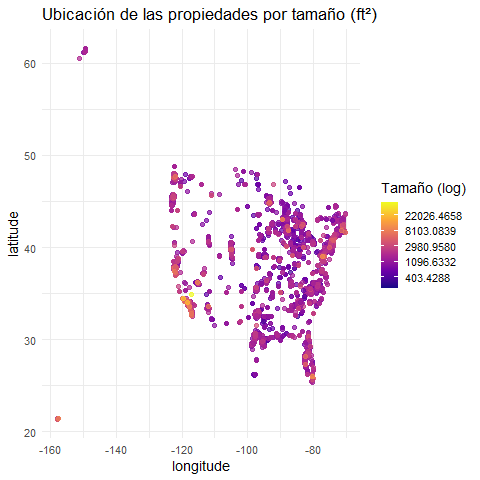

In [91]:
%%R

ggplot(dfMedidas, aes(x = longitude, y = latitude, color = price)) +
  geom_point(alpha = 0.7) +
  scale_color_viridis_c(option = "plasma", trans = "log") +
  labs(title = "Ubicación de las propiedades por tamaño (ft²)",
       color = "Tamaño (log)") +
  theme_minimal(base_size = 14)

In addition: Warning messages:
1: Removed 10 rows containing missing values or values outside the scale range
(`geom_point()`). 
2: Removed 10 rows containing missing values or values outside the scale range
(`geom_point()`). 


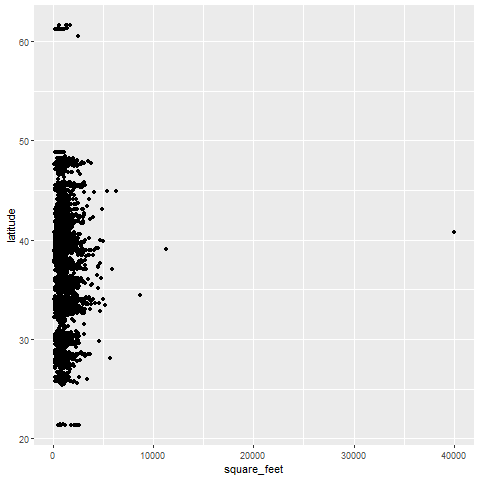

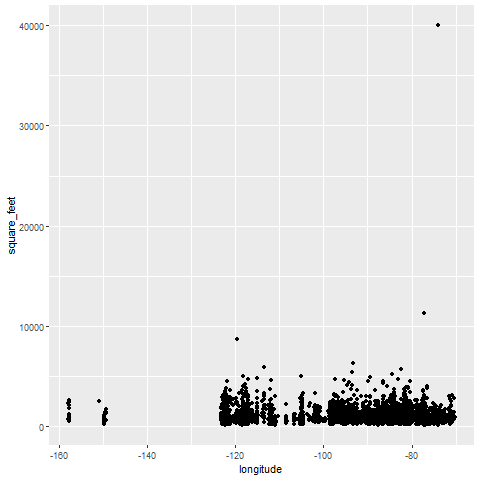

In [92]:
%%R
print(ggplot(dfMedidas, aes(x = square_feet, y = latitude)) + geom_point())
print(ggplot(dfMedidas, aes(x = longitude, y = square_feet)) + geom_point())

No hay una explicación geográfica del tamaño de las casas, por lo que se evalúa la relación con el tipo de casas (variable objetivo) 

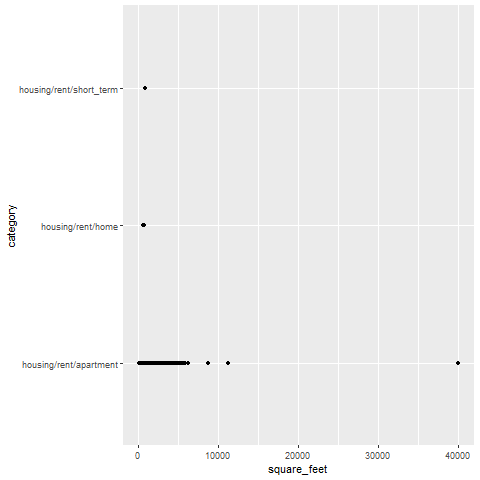

In [93]:
%%R
print(ggplot(dfMedidas, aes(x = square_feet, y = category)) + geom_point())

In [99]:
%%R
print(table(dfMedidas$category))
print(prop.table(table(dfMedidas$category))*100)


 housing/rent/apartment       housing/rent/home housing/rent/short_term 
                   9996                       2                       2 

 housing/rent/apartment       housing/rent/home housing/rent/short_term 
                  99.96                    0.02                    0.02 


De estas gráficas podemos sacar las siguientes conclusiones:

* En cuanto al precio de las viviendas, podemos observar que hay una zona geográfica que concentra los precios más altos (33/34º N, ~117º W).
* En cuanto al tamaño de las viviendas, podemos ver que las casas más grandes son de la categoria apartamento, siendo esta la categoria con más número de casas.

Por todo esto, se puede ver que los valores que en un principio pueden parecer atípicos, muestran información acerca de una concentración geográfica de casas de mayor precio, así como un mayor tamaño de una categoría concreta de casas.

## Análisis de Correlación::

### Correlación entre las variables numéricas:

In [95]:
%%R

num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
corr_test <- corr.test(num_vars)

# Correlaciones
print(round(corr_test$r, 2))


            bathrooms bedrooms price square_feet latitude longitude  time
bathrooms        1.00     0.71  0.41        0.80    -0.05      0.00

 -0.05
bedrooms         0.71     1.00  0.31        0.59     0.02      0.03  0.03
price            0.41     0.31  1.00        0.39     0.02     -0.18 -0.02
square_feet      0.80     0.59  0.39        1.00    -0.01      0.02  0.01
latitude        -0.05     0.02  0.02       -0.01     1.00     -0.11 -0.06
longitude        0.00     0.03 -0.18        0.02    -0.11      1.00 -0.19
time            -0.05     0.03 -0.02        0.01    -0.06     -0.19  1.00


Y de una forma más visual:

R callback write-console: In addition:   
R callback write-console: There were 40 warnings (use warnings() to see them)  
R callback write-console: 
  


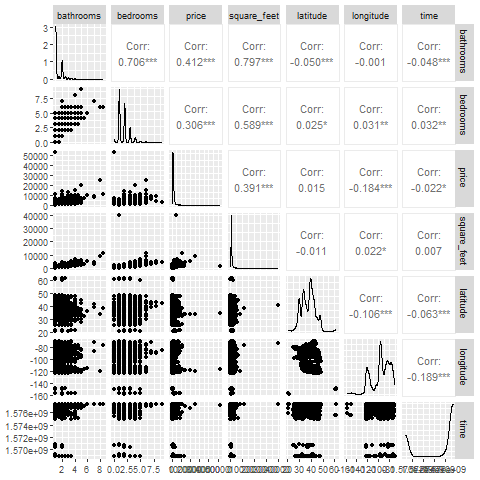

In [96]:
%%R
num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
ggpairs(num_vars)

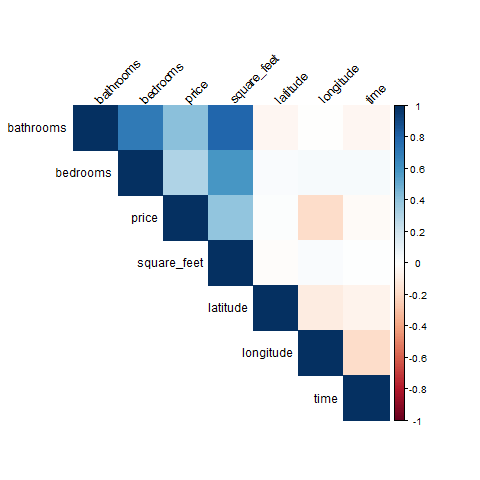

In [97]:
%%R
num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
cor_matrix <- cor(num_vars, use = "complete.obs")

corrplot(corr_test$r,
        type = "upper", 
        method = "color", 
        tl.col = "black", 
        tl.srt = 45)

Podemos ver que las variables más relacionadas son el número de baños con los metros cuadrados (80%) y con el número de dormitorios (71%). 
Por otro lado, destaca la relación del número de dormitorios con el tamaño de la vivienda (60%)

Estas relaciones tienen sentido, ya que, el tamaño de una vivienda viene dado por la suma del tamaño de sus habitaciones (dormitorios y baños), y el número de baños está directamente relacionado con el de dormitorios, pues normalmente hay casi tantos de uno como de otro.

Estas relaciones significativas habrá que tenerlas en cuenta en el futuro, ya que, la informaciñon que aportan cada una de las variables de cada par puede llegar a ser redundante.


### Correlación con la variable objetivo:

Evaluamos la correlación de las variables numéricas con la variable objetivo

In [58]:
%%R
library(ggplot2)

target <- "category"
dfMedidas[[target]] <- as.numeric(as.factor(dfMedidas[[target]])) - 1

num_vars <- dfMedidas[, sapply(dfMedidas, is.numeric)]
correlations <- cor(num_vars, use = "complete.obs", method = "pearson")[, target]

cor_df <- data.frame(
  Variable = names(correlations),
  Correlation = correlations
)
cor_df <- cor_df[cor_df$Variable != target, ]
cor_df <- cor_df[order(-abs(cor_df$Correlation)), ]

print(cor_df)

               Variable   Correlation
latitude       latitude -1.727350e-02
price             price -1.462970e-02
longitude     longitude  5.027233e-03
time               time  4.733065e-03
square_feet square_feet -3.740974e-03
bathrooms     bathrooms  3.178580e-03
bedrooms       bedrooms  4.282091e-05


Podemos ver que los valores no son lo suficientemente significativos como para que las variables afecten a la objetivo.